Scam Conversation Detection Using Clustering and Hidden Markov Models

1. Introduction

This project explores machine learning techniques for analyzing scam-related conversations using unsupervised clustering and sequential probabilistic modeling.

The objective is to investigate patterns in conversation data using multiple clustering algorithms and Hidden Markov Models (HMMs).

2. Objectives

* Apply different clustering algorithms to group similar conversations.
* Explore patterns and similarities within the conversation dataset.
* Implement Hidden Markov Models to analyze sequential patterns in conversations.
* Compare the behavior and results of different clustering and HMM approaches.
* Visualize and interpret the results obtained from the implementations.

3. Algorithms

Clustering

K-Means, Gaussian Mixture Models, Agglomerative Clustering, DBSCAN, Spectral Clustering, and hierarchical clustering with different linkage methods.

Hidden Markov Models

Discrete HMM, Forward Algorithm, Forward-Backward Algorithm, Viterbi Algorithm, Scaled Forward-Backward Algorithm, and Gaussian HMM.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("../datasets/processed/cleaned_train.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (30409, 3)

Column Names:
['text', 'label', 'cleaned_text']


In [4]:
df.head()

,text,label,cleaned_text
0,hello this is the national lottery center cong...,1,hello this is the national lottery center cong...
1,i am a traffic consultation assistant i can he...,1,i am a traffic consultation assistant i can he...
2,sez hows u de arab boy hope u r all good give ...,0,sez hows u de arab boy hope u r all good give ...
3,i like to travel domestically or international...,0,i like to travel domestically or international...
4,welcome are there any products you would like ...,1,welcome are there any products you would like ...


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30409 entries, 0 to 30408
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   text          30409 non-null  str  
 1   label         30409 non-null  int64
 2   cleaned_text  30409 non-null  str  
dtypes: int64(1), str(2)
memory usage: 712.8 KB


In [6]:
df.isnull().sum()

text            0
label           0
cleaned_text    0
dtype: int64

In [7]:
df["label"].value_counts()

label
1    19379
0    11030
Name: count, dtype: int64

In [8]:
df["label"].value_counts(normalize=True) * 100

label
1    63.727844
0    36.272156
Name: proportion, dtype: float64

## 4. Clustering

Clustering is an unsupervised machine learning technique that groups similar data points together based on their features.

In this project, TF-IDF is used to convert conversation text into numerical representations. Different clustering algorithms are then applied to identify patterns and similarities between conversations.

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    ngram_range=(1, 2)
)

X_tfidf = tfidf_vectorizer.fit_transform(df["cleaned_text"])

print("TF-IDF matrix shape:", X_tfidf.shape)

TF-IDF matrix shape: (30409, 5000)


## 4.1 K-Means Clustering

K-Means is a partition-based clustering algorithm that divides a dataset into K clusters.

The algorithm assigns each data point to the nearest cluster centroid and iteratively updates the centroids until the clusters stabilize.

In this project, K-Means is applied to TF-IDF representations of scam conversations to identify groups of similar messages.

In [10]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_tfidf)

df["KMeans_Cluster"] = kmeans_labels

print("K-Means clustering completed!")
print("Cluster distribution:")
print(df["KMeans_Cluster"].value_counts())

K-Means clustering completed!
Cluster distribution:
KMeans_Cluster
0    22165
1     8244
Name: count, dtype: int64


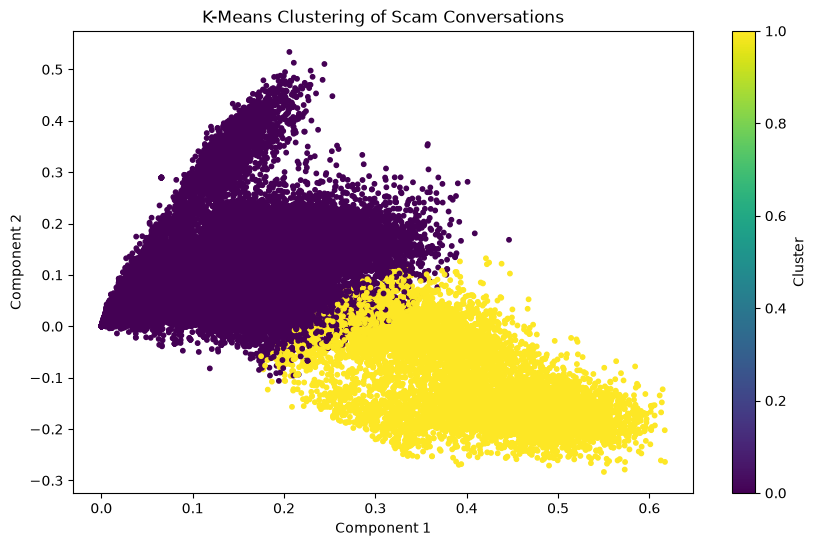

In [11]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=2, random_state=42)

X_svd = svd.fit_transform(X_tfidf)

plt.figure(figsize=(10, 6))

plt.scatter(
    X_svd[:, 0],
    X_svd[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=10
)

plt.title("K-Means Clustering of Scam Conversations")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.colorbar(label="Cluster")
plt.show()

## 4.2 Gaussian Mixture Model (GMM)

Gaussian Mixture Model is a probabilistic clustering algorithm that assumes the data is generated from a mixture of multiple Gaussian distributions.

Unlike K-Means, which assigns each data point to exactly one cluster, GMM estimates the probability that a data point belongs to each cluster.

The Expectation-Maximization (EM) algorithm is used to estimate the parameters of the Gaussian distributions.

In [12]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(
    n_components=2,
    random_state=42,
    covariance_type="diag",
    max_iter=100
)

gmm_labels = gmm.fit_predict(X_svd)

df["GMM_Cluster"] = gmm_labels

print("GMM clustering completed!")
print("Cluster distribution:")
print(df["GMM_Cluster"].value_counts())

GMM clustering completed!
Cluster distribution:
GMM_Cluster
0    23987
1     6422
Name: count, dtype: int64


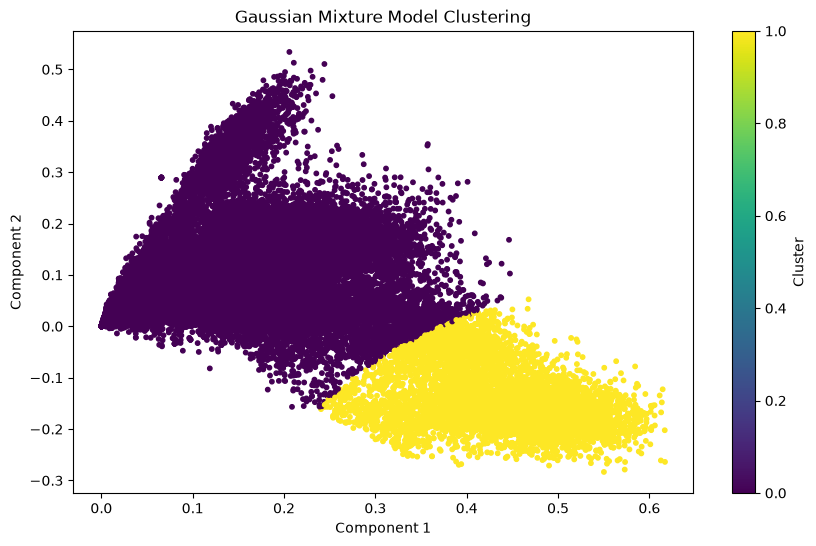

In [13]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X_svd[:, 0],
    X_svd[:, 1],
    c=gmm_labels,
    cmap="viridis",
    s=10
)

plt.title("Gaussian Mixture Model Clustering")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.colorbar(label="Cluster")
plt.show()

4.4 Agglomerative Clustering

Agglomerative Clustering is an unsupervised machine learning algorithm that groups similar data points into clusters using a bottom-up approach.

In this project, it is applied to TF-IDF features using the Ward linkage method to identify patterns and similarities between scam conversations.

In [14]:
from sklearn.cluster import AgglomerativeClustering

sample_indices = np.random.RandomState(42).choice(
    X_svd.shape[0], 5000, replace=False
)

X_sample = X_svd[sample_indices]

agg_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

agg_labels = agg_model.fit_predict(X_sample)

df.loc[df.index[sample_indices], "Agglomerative_Cluster"] = agg_labels

print("Agglomerative Clustering completed!")
print("\nCluster distribution:")
print(pd.Series(agg_labels).value_counts())

Agglomerative Clustering completed!

Cluster distribution:
0    3376
1    1624
Name: count, dtype: int64


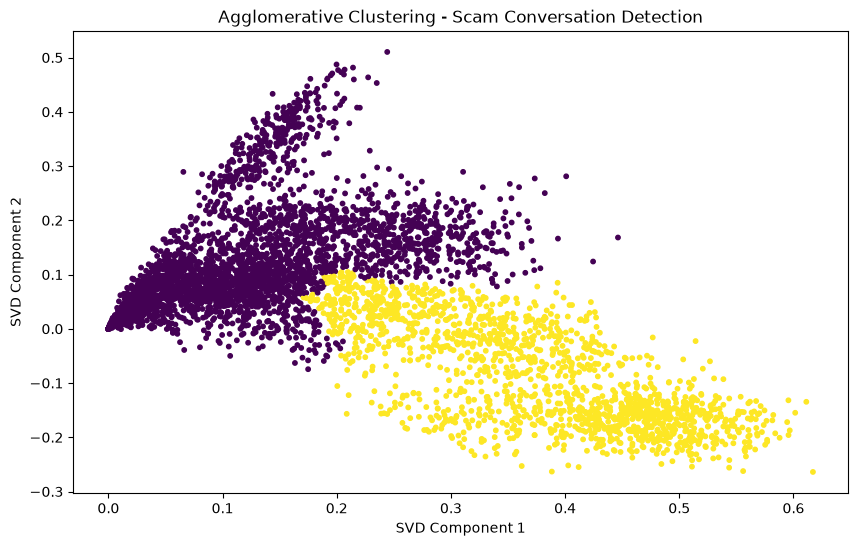

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    X_sample[:, 0],
    X_sample[:, 1],
    c=agg_labels,
    cmap="viridis",
    s=10
)

plt.title("Agglomerative Clustering - Scam Conversation Detection")
plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.show()

In [16]:
from sklearn.metrics import confusion_matrix

sample_true_labels = df["label"].iloc[sample_indices]

print(confusion_matrix(sample_true_labels, agg_labels))

[[1812    4]
 [1564 1620]]


4. Single Linkage Clustering

Single Linkage is a hierarchical clustering algorithm that groups data points based on the minimum distance between two clusters.

It starts by treating each data point as an individual cluster. At each step, it merges the two clusters that have the closest pair of points. This process continues until the desired number of clusters is obtained.

Objective: To group scam and legitimate conversations based on the similarity of their TF-IDF representations using Single Linkage clustering.

In [17]:
from sklearn.cluster import AgglomerativeClustering

single_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="single"
)

single_labels = single_model.fit_predict(X_sample)

df.loc[df.index[sample_indices], "Single_Linkage_Cluster"] = single_labels

print("Single Linkage Clustering completed!")
print(pd.Series(single_labels).value_counts())

Single Linkage Clustering completed!
0    4999
1       1
Name: count, dtype: int64


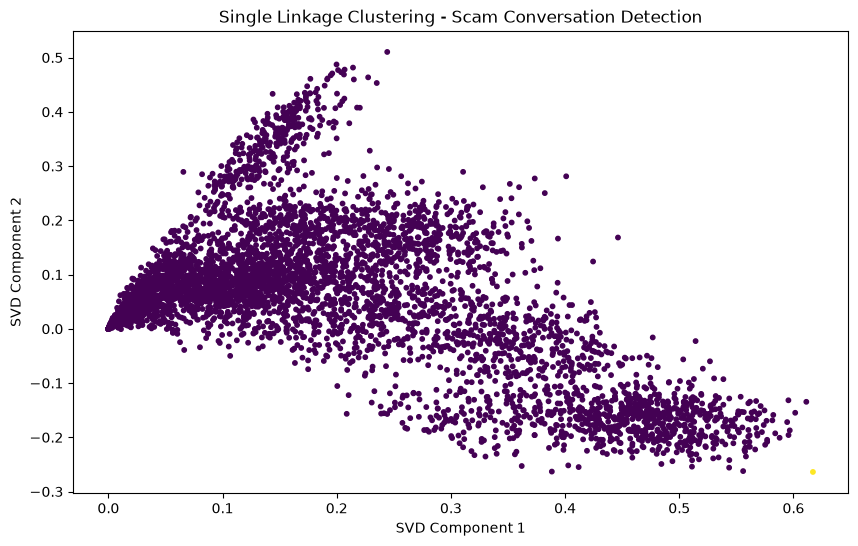

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    X_sample[:, 0],
    X_sample[:, 1],
    c=single_labels,
    cmap="viridis",
    s=10
)

plt.title("Single Linkage Clustering - Scam Conversation Detection")
plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.show()

5. Complete Linkage Clustering

Complete Linkage is a hierarchical clustering algorithm that measures the distance between two clusters using the maximum distance between any pair of points, with one point from each cluster.

At each step, it merges the two clusters with the smallest maximum distance. This generally produces more compact clusters than Single Linkage.

Objective: To group scam and legitimate conversations using Complete Linkage clustering and compare its results with other clustering algorithms.

In [19]:
from sklearn.cluster import AgglomerativeClustering

complete_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="complete"
)

complete_labels = complete_model.fit_predict(X_sample)

df.loc[df.index[sample_indices], "Complete_Linkage_Cluster"] = complete_labels

print("Complete Linkage Clustering completed!")
print(pd.Series(complete_labels).value_counts())

Complete Linkage Clustering completed!
0    3686
1    1314
Name: count, dtype: int64


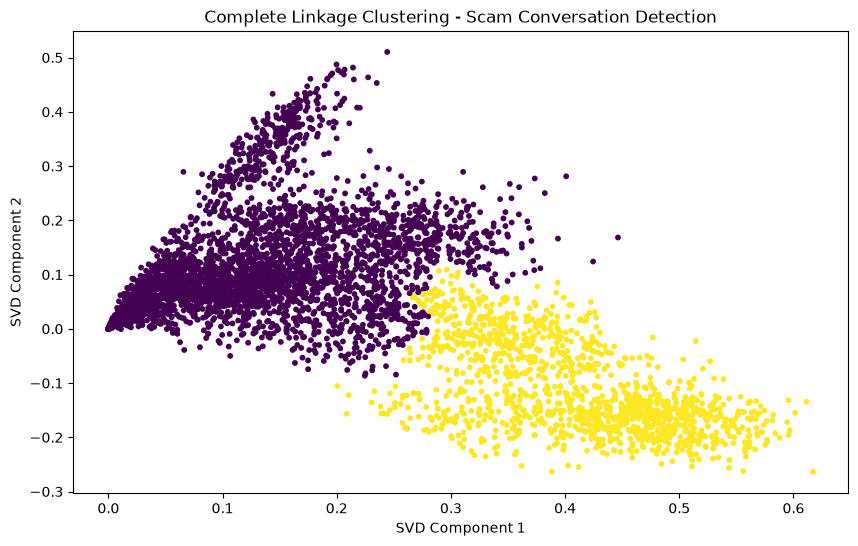

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    X_sample[:, 0],
    X_sample[:, 1],
    c=complete_labels,
    cmap="viridis",
    s=10
)

plt.title("Complete Linkage Clustering - Scam Conversation Detection")
plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.show()

6. Average Linkage Clustering

Average Linkage is a hierarchical clustering algorithm that calculates the distance between two clusters using the average distance between all pairs of data points, with one point from each cluster.

At each step, it merges the two clusters with the smallest average distance. It provides a balance between Single Linkage and Complete Linkage.

Objective: To group scam and legitimate conversations using Average Linkage clustering and observe the resulting cluster structure.

In [21]:
from sklearn.cluster import AgglomerativeClustering

average_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="average"
)

average_labels = average_model.fit_predict(X_sample)

df.loc[df.index[sample_indices], "Average_Linkage_Cluster"] = average_labels

print("Average Linkage Clustering completed!")
print(pd.Series(average_labels).value_counts())

Average Linkage Clustering completed!
0    3660
1    1340
Name: count, dtype: int64


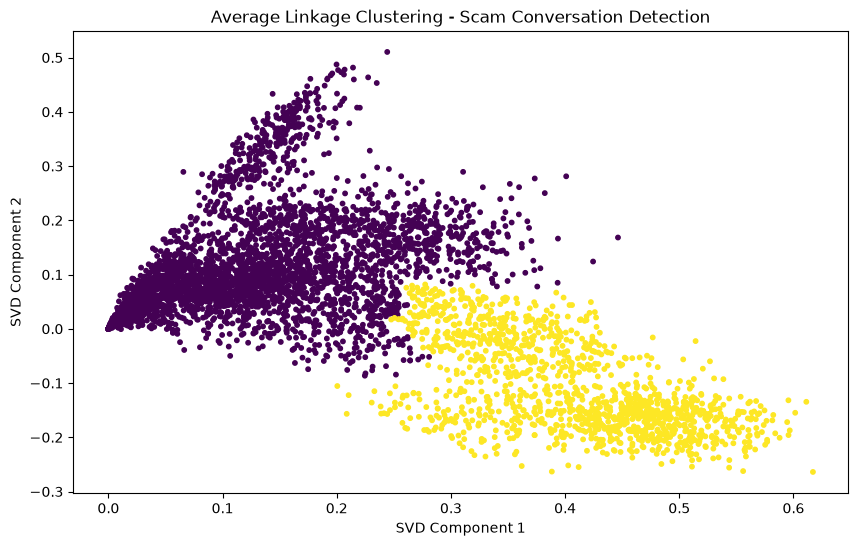

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    X_sample[:, 0],
    X_sample[:, 1],
    c=average_labels,
    cmap="viridis",
    s=10
)

plt.title("Average Linkage Clustering - Scam Conversation Detection")
plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.show()

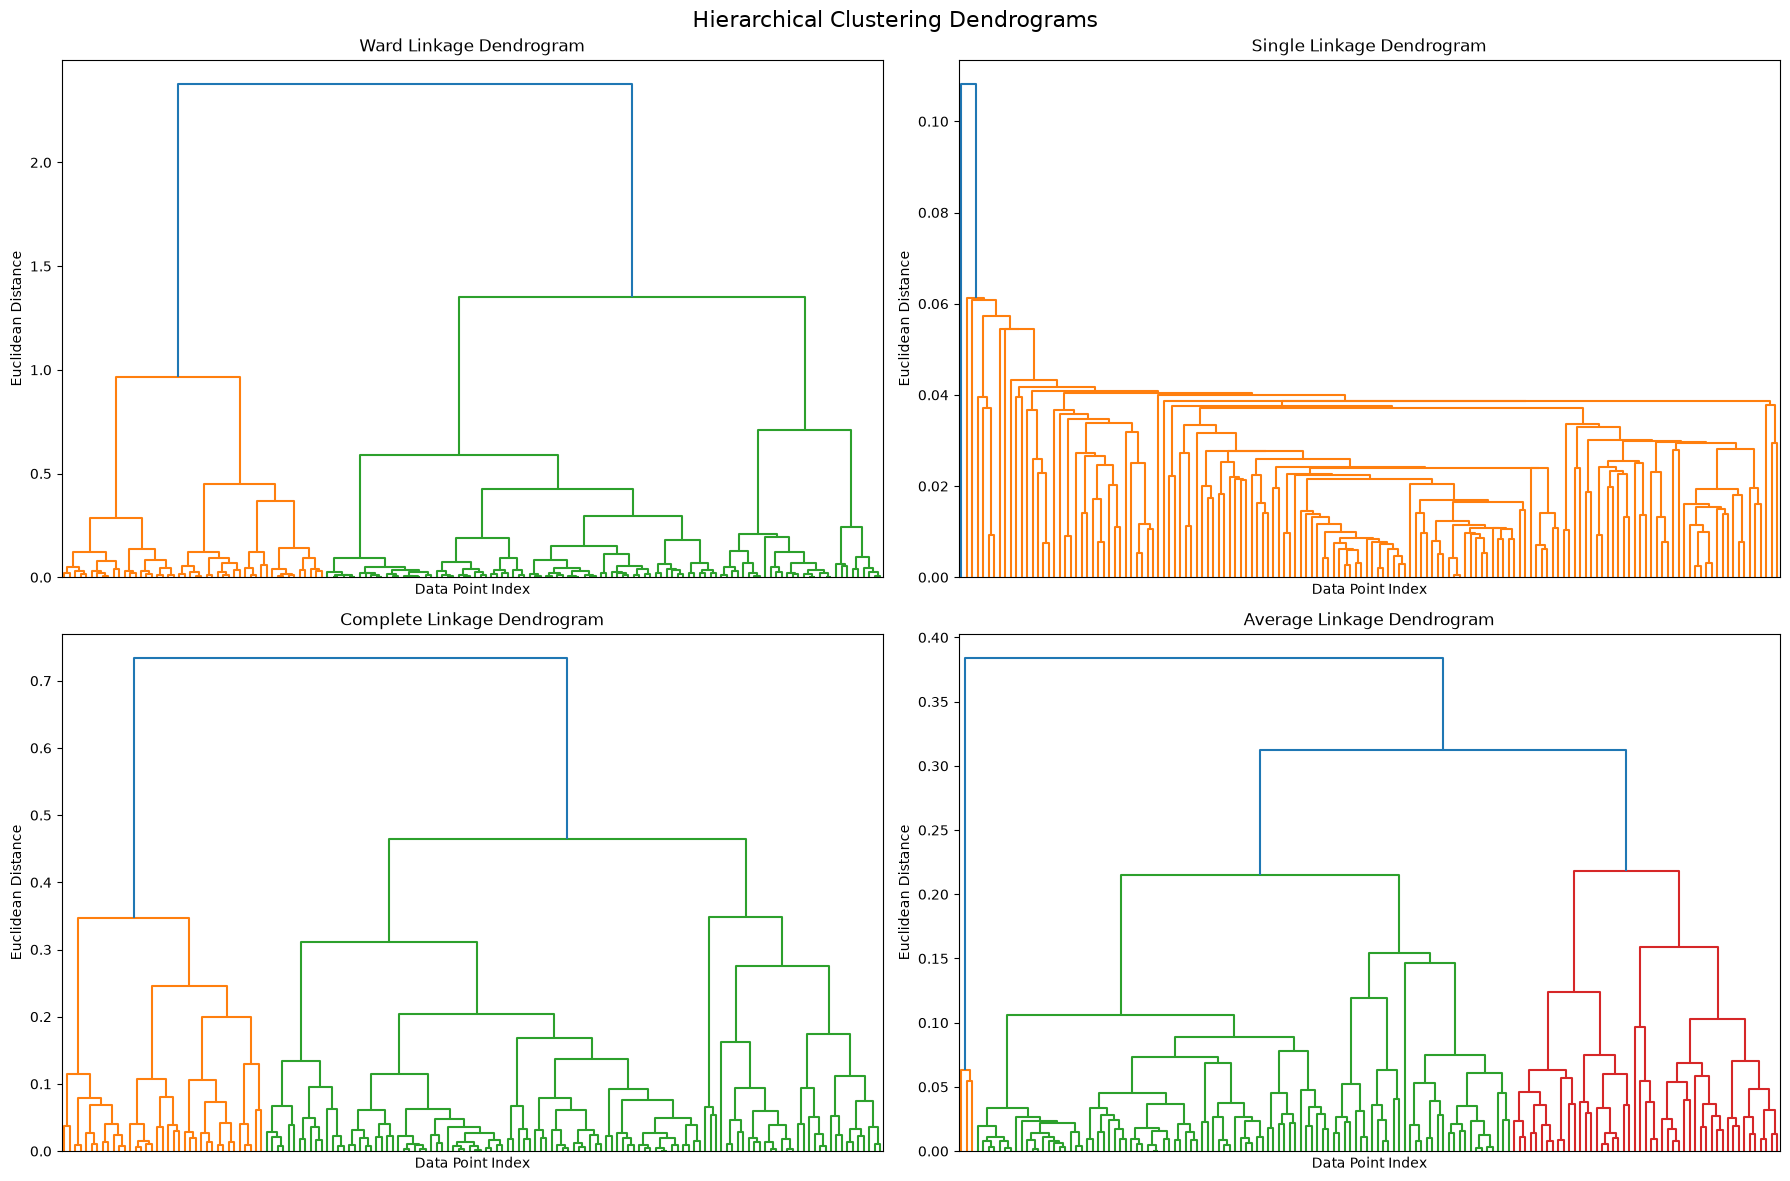

In [23]:

import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

# Use a smaller sample to keep dendrograms readable
n_points = min(150, len(X_sample))
X_dendro = X_sample[:n_points]

linkage_methods = ["ward", "single", "complete", "average"]

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes = axes.flatten()

for ax, method in zip(axes, linkage_methods):
    # Calculate hierarchical clustering
    Z = linkage(X_dendro, method=method, metric="euclidean")

    # Draw dendrogram
    dendrogram(
        Z,
        ax=ax,
        no_labels=True,
        color_threshold=None
    )

    ax.set_title(f"{method.capitalize()} Linkage Dendrogram")
    ax.set_xlabel("Data Point Index")
    ax.set_ylabel("Euclidean Distance")

plt.suptitle(
    "Hierarchical Clustering Dendrograms",
    fontsize=16
)
plt.tight_layout()
plt.show()

7. Spectral Clustering

Spectral Clustering is a clustering algorithm that uses the similarity relationships between data points to group them into clusters.

It constructs a similarity graph, transforms the data using eigenvectors of a graph-based matrix, and then applies a clustering algorithm such as K-Means to the transformed representation.

Objective: To group scam and legitimate conversations based on their similarity relationships and visualize the resulting clusters.

In [24]:
from sklearn.cluster import SpectralClustering

spectral_model = SpectralClustering(
    n_clusters=2,
    affinity="nearest_neighbors",
    n_neighbors=10,
    random_state=42
)

spectral_labels = spectral_model.fit_predict(X_sample)

df.loc[df.index[sample_indices], "Spectral_Cluster"] = spectral_labels

print("Spectral Clustering completed!")
print(pd.Series(spectral_labels).value_counts())

Spectral Clustering completed!
0    3718
1    1282
Name: count, dtype: int64


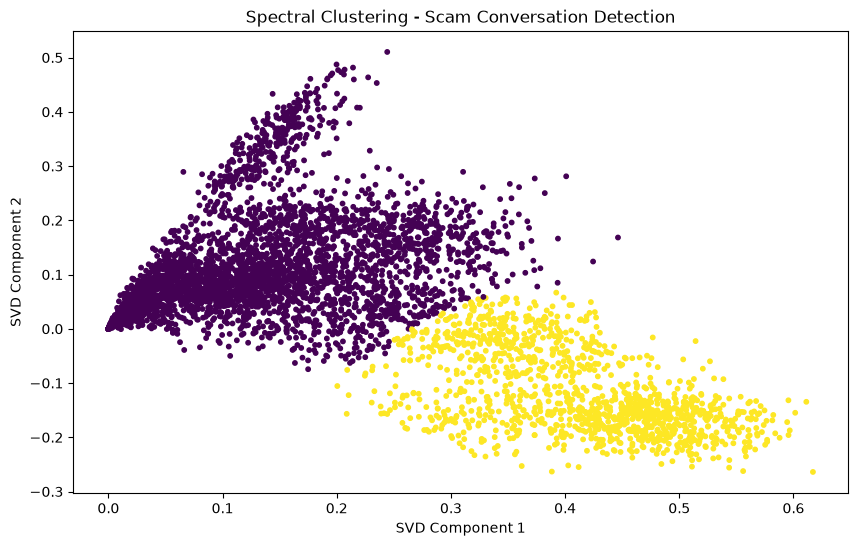

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    X_sample[:, 0],
    X_sample[:, 1],
    c=spectral_labels,
    cmap="viridis",
    s=10
)

plt.title("Spectral Clustering - Scam Conversation Detection")
plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.show()

8. Birch Clustering

BIRCH (Balanced Iterative Reducing and Clustering using Hierarchies) is a hierarchical clustering algorithm designed to handle large datasets efficiently.

It builds a compact representation of the data using a Clustering Feature (CF) tree. These features summarize groups of data points, allowing the algorithm to perform clustering without repeatedly processing every individual point.

Objective: To group scam and legitimate conversations using Birch clustering and visualize the resulting clusters.

In [26]:
from sklearn.cluster import Birch
birch_model = Birch(
    threshold=0.1,
    branching_factor=50,
    n_clusters=2
)

birch_labels = birch_model.fit_predict(X_sample)

print("Birch Clustering completed!")
print(pd.Series(birch_labels).value_counts())

Birch Clustering completed!
0    4097
1     903
Name: count, dtype: int64


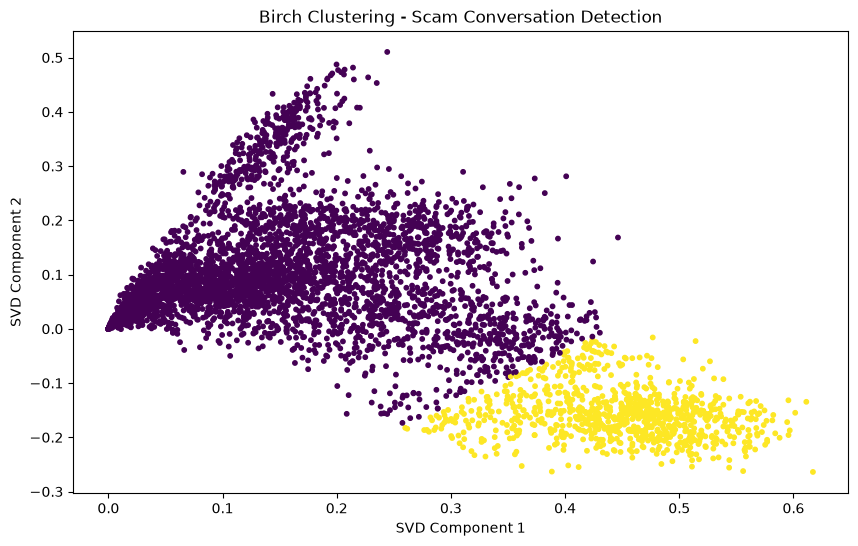

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    X_sample[:, 0],
    X_sample[:, 1],
    c=birch_labels,
    cmap="viridis",
    s=10
)

plt.title("Birch Clustering - Scam Conversation Detection")
plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.show()

Clustering Comparison and Evaluation

Objective

The main objective of this experiment is to identify patterns and similarities among scam and legitimate conversations using unsupervised clustering algorithms.

The TF-IDF representation of the cleaned conversation text is used to capture the importance of words and phrases. Dimensionality reduction using Truncated SVD provides a two-dimensional representation for visualizing the clustering results.

Eight clustering methods are implemented and compared:

1. K-Means
2. Gaussian Mixture Model (GMM)
3. Agglomerative Clustering using Ward Linkage
4. Single Linkage
5. Complete Linkage
6. Average Linkage
7. Spectral Clustering
8. BIRCH

Evaluation Parameters

The algorithms are evaluated using the following parameters:

* Silhouette Score: Measures how well data points fit within their assigned clusters compared with other clusters. Higher values generally indicate better-separated clusters.
* Davies-Bouldin Index: Measures cluster similarity and compactness. Lower values generally indicate better clustering.
* Calinski-Harabasz Score: Measures the separation between clusters relative to the variation within clusters. Higher values generally indicate better-defined clusters.
* Cluster Balance: Examines whether the algorithms produce meaningful groups or assign almost all conversations to one cluster.
* Scam Detection Alignment: Compares the unsupervised cluster assignments against the actual scam labels using Adjusted Rand Index (ARI). Higher values indicate stronger agreement, without requiring the cluster IDs to match the label IDs.

These metrics are used to compare the clustering methods and identify which algorithms produce the most useful grouping of conversations.

In [28]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

cluster_results = {
    "K-Means": kmeans_labels,
    "GMM": gmm_labels,
    "Agglomerative (Ward)": agg_labels,
    "Single Linkage": single_labels,
    "Complete Linkage": complete_labels,
    "Average Linkage": average_labels,
    "Spectral Clustering": spectral_labels,
    "BIRCH": birch_labels
}

comparison_results = []

for name, labels in cluster_results.items():

    labels = np.asarray(labels)

    if len(labels) == len(df):
        labels = labels[sample_indices]

    if len(labels) != len(X_sample):
        print(f"Skipping {name}: label length does not match sample")
        continue

    unique_labels, counts = np.unique(labels, return_counts=True)

    number_of_clusters = len(unique_labels)

    if number_of_clusters > 1 and number_of_clusters < len(labels):

        silhouette = silhouette_score(X_sample, labels)
        db_index = davies_bouldin_score(X_sample, labels)
        ch_score = calinski_harabasz_score(X_sample, labels)
        ari = adjusted_rand_score(sample_true_labels, labels)

    else:
        silhouette = np.nan
        db_index = np.nan
        ch_score = np.nan
        ari = np.nan

    comparison_results.append({
        "Algorithm": name,
        "Clusters": number_of_clusters,
        "Smallest Cluster": counts.min(),
        "Largest Cluster": counts.max(),
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": db_index,
        "Calinski-Harabasz Score": ch_score,
        "Adjusted Rand Index": ari
    })

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by="Silhouette Score",
    ascending=False,
    na_position="last"
)

comparison_df.round(4)

,Algorithm,Clusters,Smallest Cluster,Largest Cluster,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score,Adjusted Rand Index
1,GMM,2,1059,3941,0.5831,0.5300,7468.7913,-0.0026
6,Spectral Clustering,2,1282,3718,0.5829,0.5904,8145.4619,0.0400
4,Complete Linkage,2,1314,3686,0.5751,0.6068,7980.7153,0.0465
0,K-Means,2,1358,3642,0.5719,0.6196,7989.1448,0.0578
5,Average Linkage,2,1340,3660,0.5699,0.6178,7883.5744,0.0526
7,BIRCH,2,903,4097,0.5687,0.4986,6404.6672,-0.0237
2,Agglomerative (Ward),2,1624,3376,0.5124,0.7359,6703.8559,0.1309
3,Single Linkage,2,1,4999,0.4456,0.3385,6.7070,-0.0002


Conclusion

Eight clustering methods were implemented and evaluated for scam conversation detection.

Among the tested methods, GMM achieved the highest Silhouette Score of 0.5831, while K-Means achieved the highest Adjusted Rand Index of 0.0578.

The clustering metrics indicate that some algorithms produce reasonably separated groups, but their agreement with the actual scam and legitimate labels remains low.

Therefore, clustering can help explore patterns and similarities in scam conversations, but the results do not demonstrate reliable scam classification. Further supervised learning and analysis of the conversation features would be required to improve scam detection.

Silhouette Score Comparison

The Silhouette Score is used to compare the quality of the clusters generated by different clustering algorithms. A higher score generally indicates that data points are more similar to their assigned clusters and better separated from other clusters.

This visualization compares the Silhouette Scores of all eight clustering algorithms.

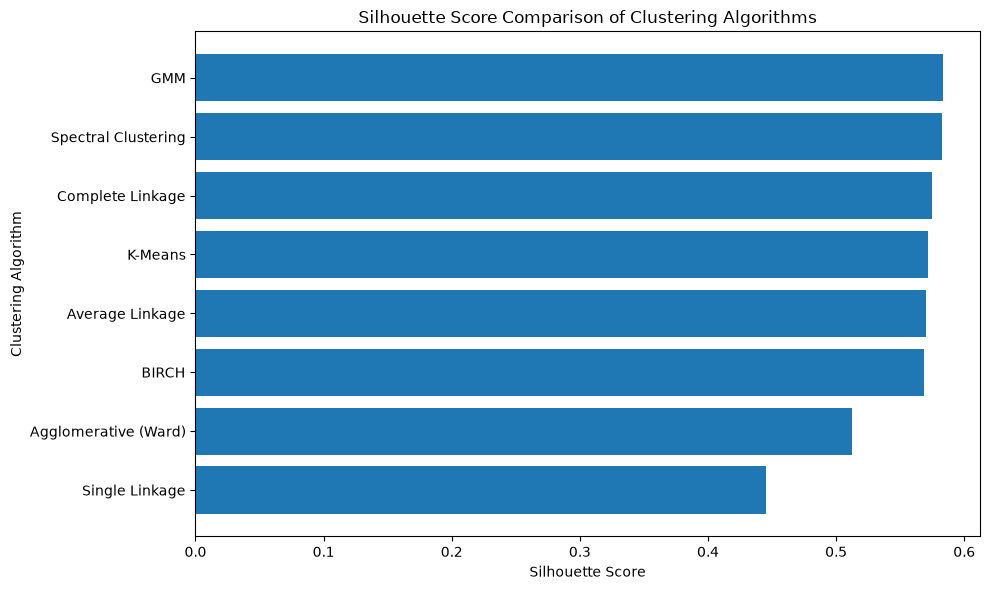

In [29]:
import matplotlib.pyplot as plt

plot_df = comparison_df.sort_values(
    "Silhouette Score",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Algorithm"],
    plot_df["Silhouette Score"]
)

plt.title("Silhouette Score Comparison of Clustering Algorithms")
plt.xlabel("Silhouette Score")
plt.ylabel("Clustering Algorithm")
plt.tight_layout()
plt.show()

Cluster Distribution Comparison

This visualization compares the number of conversations assigned to each cluster by the different clustering algorithms.

It helps identify algorithms that produce balanced clusters and algorithms that assign most conversations to a single cluster.

A highly imbalanced cluster distribution may indicate that an algorithm is not effectively separating the conversations into meaningful groups.

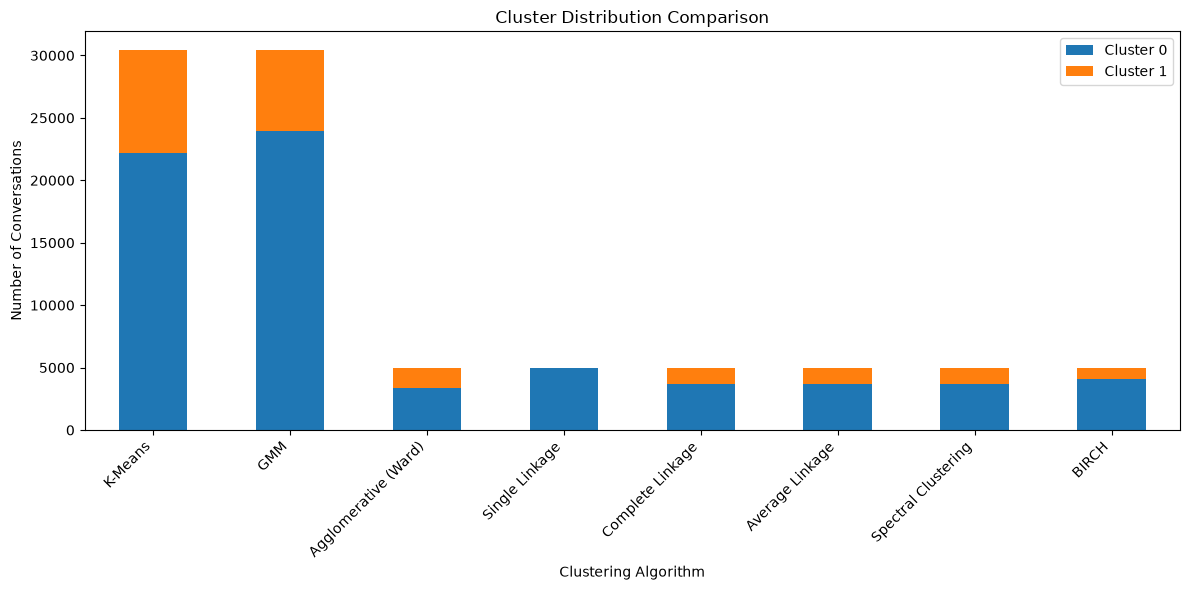

In [30]:
import matplotlib.pyplot as plt
import pandas as pd

cluster_distribution = pd.DataFrame({
    name: pd.Series(labels).value_counts().sort_index()
    for name, labels in cluster_results.items()
}).T

cluster_distribution.columns = [
    f"Cluster {cluster_id}"
    for cluster_id in cluster_distribution.columns
]

cluster_distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Cluster Distribution Comparison")
plt.xlabel("Clustering Algorithm")
plt.ylabel("Number of Conversations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Hidden Markov Models for Scam Conversation Detection

Introduction

A Hidden Markov Model (HMM) is a probabilistic model used to represent sequential data. It assumes that the observed data is generated by a sequence of hidden states, where each hidden state produces an observable output.

In scam conversation detection, the words in a conversation can be treated as observations, while the underlying conversational behavior can be represented using hidden states.

An HMM consists of:

* Hidden States: The underlying states that cannot be directly observed.
* Observations: The words or tokens observed in a conversation.
* Transition Probabilities: The probabilities of moving from one hidden state to another.
* Emission Probabilities: The probabilities of observing a particular word given a hidden state.
* Initial State Probabilities: The probabilities of starting in each hidden state.

Objective

To explore sequential patterns in scam and legitimate conversations using Hidden Markov Models and evaluate how hidden-state sequences represent conversational behavior.

In [31]:
import numpy as np
import pandas as pd

conversation_sequences = df["cleaned_text"].fillna("").apply(
    lambda text: text.split()
)

print("Total conversations:", len(conversation_sequences))
print("\nFirst conversation:")
print(conversation_sequences.iloc[0][:30])

Total conversations: 30409

First conversation:
['hello', 'this', 'is', 'the', 'national', 'lottery', 'center', 'congratulations', 'on', 'winning', 'this', 'issues', 'jackpot', 'with', 'a', 'prize', 'of', 'up', 'to', '<number>', 'million', 'rupees', 'please', 'confirm', 'your', 'personal', 'information', 'so', 'that', 'we']


Discrete Hidden Markov Model

A Discrete Hidden Markov Model is a probabilistic model that represents sequential observations using a finite set of hidden states.

In this experiment, words from scam conversations are treated as observations. The model assumes that each observation is generated by a hidden state, and the hidden states follow a transition probability distribution.

The model consists of:

* Initial state probabilities
* State transition probabilities
* Observation emission probabilities

Objective: To implement a Discrete HMM and understand how hidden states and observation sequences are represented in scam conversation data.

In [32]:
%pip install hmmlearn

Note: you may need to restart the kernel to use updated packages.


In [33]:
from hmmlearn import hmm
from collections import Counter
import numpy as np

sample_texts = df["cleaned_text"].fillna("").iloc[:1000]

tokenized_conversations = [
    text.split() for text in sample_texts
]

word_frequency = Counter(
    word
    for conversation in tokenized_conversations
    for word in conversation
)

vocabulary = [
    word for word, count in word_frequency.most_common(100)
]

word_to_id = {
    word: index
    for index, word in enumerate(vocabulary)
}

observation_sequences = [
    np.array(
        [word_to_id[word] for word in conversation if word in word_to_id],
        dtype=int
    ).reshape(-1, 1)
    for conversation in tokenized_conversations
]

observation_sequences = [
    sequence
    for sequence in observation_sequences
    if len(sequence) > 0
]

lengths = [
    len(sequence)
    for sequence in observation_sequences
]

X_observations = np.concatenate(observation_sequences)

discrete_hmm = hmm.CategoricalHMM(
    n_components=2,
    n_iter=100,
    random_state=42
)

discrete_hmm.fit(X_observations, lengths)

print("Discrete HMM trained successfully!")
print("Number of conversations:", len(observation_sequences))
print("Vocabulary size:", len(vocabulary))
print("Hidden states:", discrete_hmm.n_components)
print("Initial probabilities:", discrete_hmm.startprob_)
print("Transition matrix:")
print(discrete_hmm.transmat_)
print("Emission matrix shape:", discrete_hmm.emissionprob_.shape)


Discrete HMM trained successfully!
Number of conversations: 992
Vocabulary size: 100
Hidden states: 2
Initial probabilities: [0.89380917 0.10619083]
Transition matrix:
[[0.49748198 0.50251802]
 [0.912248   0.087752  ]]
Emission matrix shape: (2, 100)


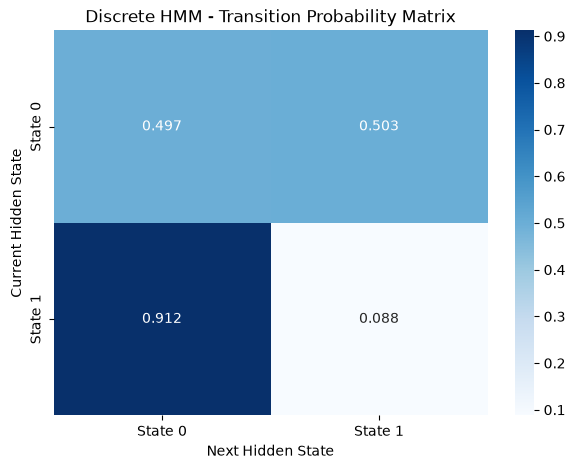

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.heatmap(
    discrete_hmm.transmat_,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    xticklabels=["State 0", "State 1"],
    yticklabels=["State 0", "State 1"]
)

plt.title("Discrete HMM - Transition Probability Matrix")
plt.xlabel("Next Hidden State")
plt.ylabel("Current Hidden State")
plt.show()

Forward Algorithm

The Forward Algorithm is a dynamic programming algorithm used in Hidden Markov Models to calculate the probability of an observation sequence given the model.

It calculates the probability of observing a sequence by considering all possible hidden-state paths and combining their probabilities.

The algorithm uses forward probabilities, which represent the probability of observing the sequence up to a particular time step and ending in a particular hidden state.

Objective: To calculate the probability of an observation sequence using the trained Discrete Hidden Markov Model.

In [35]:
sequence = observation_sequences[0].flatten()

forward_probabilities = np.zeros(
    (len(sequence), discrete_hmm.n_components)
)

forward_probabilities[0] = (
    discrete_hmm.startprob_
    * discrete_hmm.emissionprob_[:, sequence[0]]
)

for t in range(1, len(sequence)):
    for j in range(discrete_hmm.n_components):
        forward_probabilities[t, j] = (
            np.sum(
                forward_probabilities[t - 1]
                * discrete_hmm.transmat_[:, j]
            )
            * discrete_hmm.emissionprob_[j, sequence[t]]
        )

forward_probability = np.sum(forward_probabilities[-1])

print("Sequence length:", len(sequence))
print("Forward probability:", forward_probability)
print("Log probability:", np.log(forward_probability))

Sequence length: 121
Forward probability: 3.795292499860477e-226
Log probability: -519.0504695337148


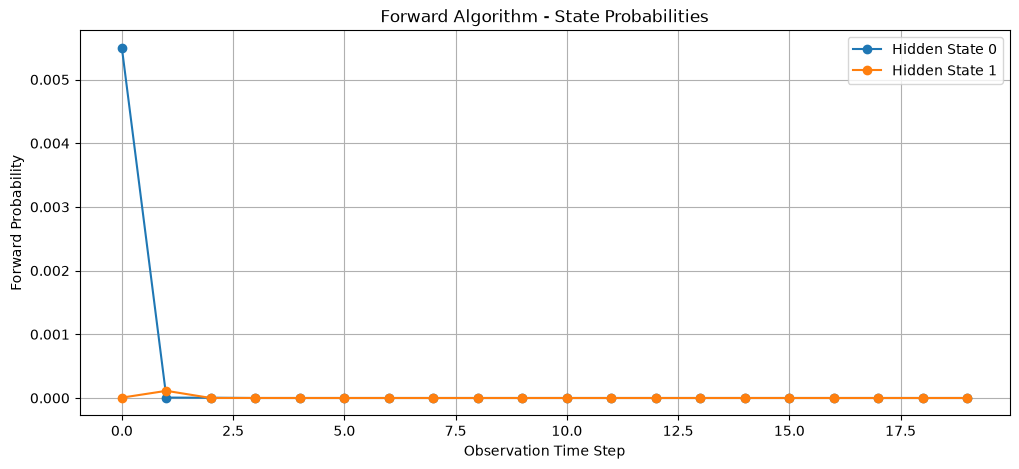

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    forward_probabilities[:20, 0],
    marker="o",
    label="Hidden State 0"
)

plt.plot(
    forward_probabilities[:20, 1],
    marker="o",
    label="Hidden State 1"
)

plt.title("Forward Algorithm - State Probabilities")
plt.xlabel("Observation Time Step")
plt.ylabel("Forward Probability")
plt.legend()
plt.grid(True)
plt.show()


Backward Algorithm

The Backward Algorithm is a dynamic programming algorithm used in Hidden Markov Models to calculate the probability of the remaining observations given a particular hidden state at a specific time step.

It works backward through the observation sequence, starting from the final time step and calculating the probability of future observations for each hidden state.

Objective: To calculate backward probabilities for an observation sequence using the trained Discrete Hidden Markov Model.

In [37]:
backward_probabilities = np.zeros(
    (len(sequence), discrete_hmm.n_components)
)

backward_probabilities[-1] = np.ones(
    discrete_hmm.n_components
)

for t in range(len(sequence) - 2, -1, -1):
    for i in range(discrete_hmm.n_components):
        backward_probabilities[t, i] = np.sum(
            discrete_hmm.transmat_[i]
            * discrete_hmm.emissionprob_[:, sequence[t + 1]]
            * backward_probabilities[t + 1]
        )

print("Backward probability matrix shape:", backward_probabilities.shape)
print("Backward probabilities at first observation:")
print(backward_probabilities[0])

Backward probability matrix shape: (121, 2)
Backward probabilities at first observation:
[6.90544270e-224 1.55081823e-224]


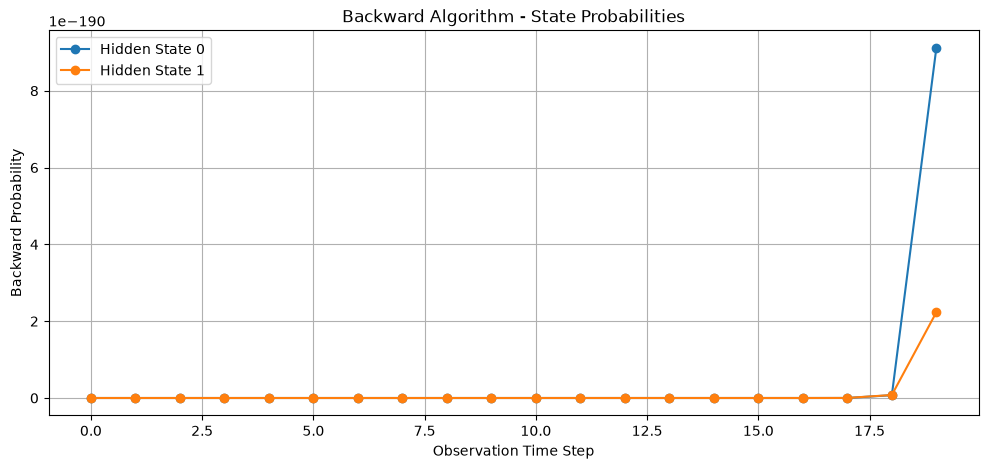

In [38]:
plt.figure(figsize=(12, 5))

plt.plot(
    backward_probabilities[:20, 0],
    marker="o",
    label="Hidden State 0"
)

plt.plot(
    backward_probabilities[:20, 1],
    marker="o",
    label="Hidden State 1"
)

plt.title("Backward Algorithm - State Probabilities")
plt.xlabel("Observation Time Step")
plt.ylabel("Backward Probability")
plt.legend()
plt.grid(True)
plt.show()

Viterbi Algorithm

The Viterbi Algorithm is a dynamic programming algorithm used in Hidden Markov Models to identify the most likely sequence of hidden states responsible for generating an observation sequence.

Unlike the Forward Algorithm, which calculates the total probability of all possible hidden-state paths, Viterbi finds the single most probable path.

Objective: To identify the most likely hidden-state sequence for a conversation using the trained Discrete Hidden Markov Model.

In [39]:
viterbi_log_probability, hidden_states = discrete_hmm.decode(
    sequence.reshape(-1, 1),
    algorithm="viterbi"
)

print("Most likely hidden state sequence:")
print(hidden_states)

print("\nSequence length:", len(hidden_states))
print("Viterbi log probability:", viterbi_log_probability)

print("\nHidden state counts:")
print(np.bincount(hidden_states, minlength=2))

Most likely hidden state sequence:
[0 1 0 1 0 1 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 0 1 0 1 0 1 0 1 0 0 0 1 0 1 0 1
 0 1 0 1 0 0 1 1 0 0 1 0 0 1 0 0 1 0 0 0 0 1 0 1 0 0 1 0 1 0 0 1 0 0 0 1 1
 0 1 0 1 0 1 0 0 0 1 0 0 1 0 0 1 0 1 0 0 1 0 0 1 0 1 0 1 1 0 1 0 1 0 0 0 1
 0 0 1 0 1 0 1 0 0 0]

Sequence length: 121
Viterbi log probability: -531.7632598852912

Hidden state counts:
[73 48]


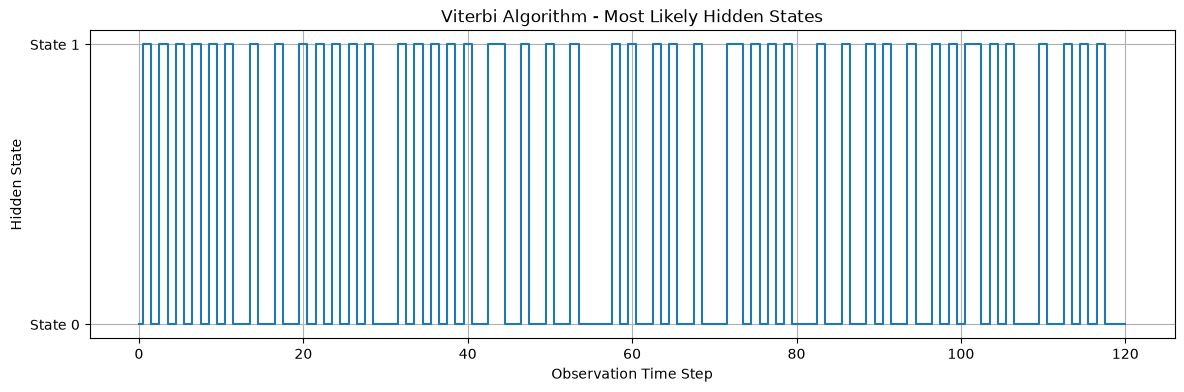

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 4))

plt.step(
    range(len(hidden_states)),
    hidden_states,
    where="mid"
)

plt.title("Viterbi Algorithm - Most Likely Hidden States")
plt.xlabel("Observation Time Step")
plt.ylabel("Hidden State")
plt.yticks([0, 1], ["State 0", "State 1"])
plt.grid(True)
plt.show()

Forward–Backward Algorithm

The Forward–Backward Algorithm is used in Hidden Markov Models to estimate the probability of being in a particular hidden state at each time step, given the entire observation sequence.

It combines:

* Forward probabilities: The probability of observing the sequence up to the current time step and ending in a particular state.
* Backward probabilities: The probability of observing the remaining sequence, given the current hidden state.

By combining these probabilities, the algorithm calculates the posterior probability of each hidden state at each time step.

Objective: To estimate the hidden-state probabilities for a conversation using the Forward–Backward Algorithm.

In [41]:
forward_backward = np.zeros(
    (len(sequence), discrete_hmm.n_components)
)

for t in range(len(sequence)):
    forward_backward[t] = (
        forward_probabilities[t] * backward_probabilities[t]
    ) / forward_probability

print("Posterior probability matrix shape:", forward_backward.shape)

print("\nPosterior probabilities at first observation:")
print(forward_backward[0])

print("\nPosterior probabilities at last observation:")
print(forward_backward[-1])

Posterior probability matrix shape: (121, 2)

Posterior probabilities at first observation:
[9.99769951e-01 2.30048720e-04]

Posterior probabilities at last observation:
[9.99294141e-01 7.05859037e-04]


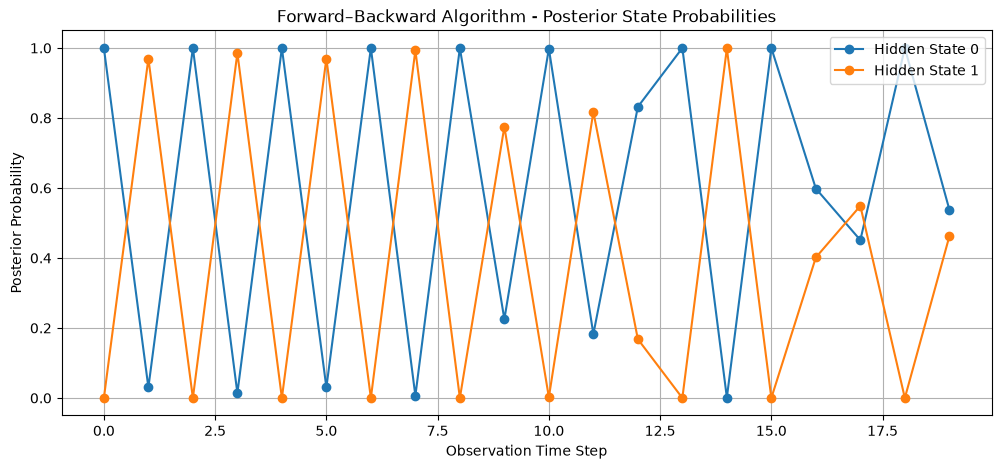

In [42]:
plt.figure(figsize=(12, 5))

plt.plot(
    forward_backward[:20, 0],
    marker="o",
    label="Hidden State 0"
)

plt.plot(
    forward_backward[:20, 1],
    marker="o",
    label="Hidden State 1"
)

plt.title("Forward–Backward Algorithm - Posterior State Probabilities")
plt.xlabel("Observation Time Step")
plt.ylabel("Posterior Probability")
plt.legend()
plt.grid(True)
plt.show()

Baum–Welch Algorithm

The Baum–Welch Algorithm is an Expectation-Maximization (EM) algorithm used to estimate the parameters of a Hidden Markov Model when the hidden states are unknown.

It iteratively updates the initial state probabilities, transition probabilities, and emission probabilities to maximize the likelihood of the observed sequences.

Objective: To train a Discrete HMM using the Baum–Welch algorithm and observe how the model parameters change during training.

In [43]:
from hmmlearn import hmm
import numpy as np

X_baum = np.concatenate(observation_sequences)

lengths_baum = [
    len(seq) for seq in observation_sequences
]

baum_welch_hmm = hmm.CategoricalHMM(
    n_components=2,
    n_iter=100,
    random_state=42
)

baum_welch_hmm.fit(X_baum, lengths_baum)

print("Baum-Welch training completed!")

print("\nInitial probabilities:")
print(baum_welch_hmm.startprob_)

print("\nTransition matrix:")
print(baum_welch_hmm.transmat_)

print("\nEmission matrix shape:")
print(baum_welch_hmm.emissionprob_.shape)

print("\nConvergence:")
print(baum_welch_hmm.monitor_.converged)

Baum-Welch training completed!

Initial probabilities:
[0.89380917 0.10619083]

Transition matrix:
[[0.49748198 0.50251802]
 [0.912248   0.087752  ]]

Emission matrix shape:
(2, 100)

Convergence:
True


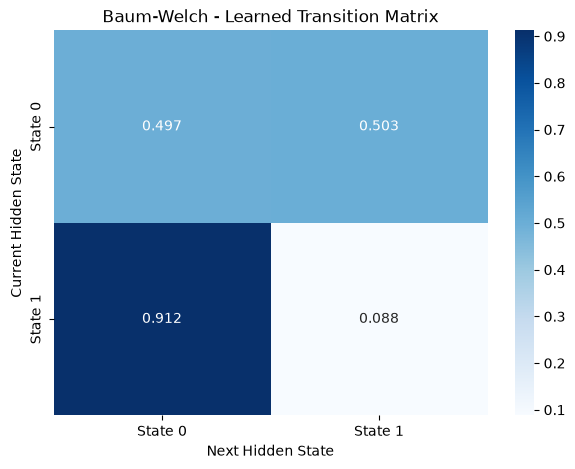

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.heatmap(
    baum_welch_hmm.transmat_,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    xticklabels=["State 0", "State 1"],
    yticklabels=["State 0", "State 1"]
)

plt.title("Baum-Welch - Learned Transition Matrix")
plt.xlabel("Next Hidden State")
plt.ylabel("Current Hidden State")
plt.show()

Gaussian Hidden Markov Model

A Gaussian Hidden Markov Model is a type of Hidden Markov Model in which the observations associated with each hidden state follow a Gaussian (normal) distribution.

Unlike a Discrete HMM, which uses discrete observation symbols, a Gaussian HMM models continuous numerical observations using state-specific means and covariance matrices.

Objective: To implement a Gaussian HMM using numerical features extracted from scam conversations and visualize the learned hidden-state transition probabilities.

In [45]:
from hmmlearn.hmm import GaussianHMM

# Initialize the Gaussian HMM
gaussian_hmm = GaussianHMM(
    n_components=2,
    covariance_type="diag",
    n_iter=100,
    random_state=42
)

# Train on the continuous numerical SVD features
gaussian_hmm.fit(X_svd)

print("Gaussian HMM model trained!")

Gaussian HMM model trained!


In [46]:
print("Gaussian HMM trained successfully!")

print("\nNumber of hidden states:")
print(gaussian_hmm.n_components)

print("\nInitial probabilities:")
print(gaussian_hmm.startprob_)

print("\nTransition matrix:")
print(gaussian_hmm.transmat_)

print("\nState means:")
print(gaussian_hmm.means_)

print("\nConvergence:")
print(gaussian_hmm.monitor_.converged)

Gaussian HMM trained successfully!

Number of hidden states:
2

Initial probabilities:
[1.00000000e+00 4.99271669e-15]

Transition matrix:
[[0.79798385 0.20201615]
 [0.78909154 0.21090846]]

State means:
[[ 0.1481418   0.10675692]
 [ 0.43977101 -0.14578363]]

Convergence:
True


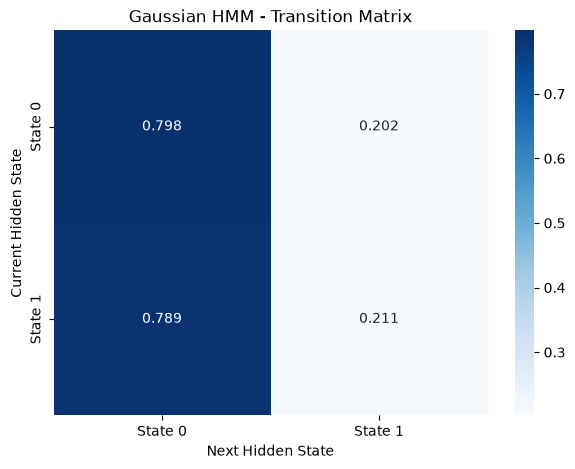

In [47]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    gaussian_hmm.transmat_,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    xticklabels=["State 0", "State 1"],
    yticklabels=["State 0", "State 1"]
)

plt.title("Gaussian HMM - Transition Matrix")
plt.xlabel("Next Hidden State")
plt.ylabel("Current Hidden State")
plt.show()

HMM Results and Comparison

The HMM section explored hidden-state modeling and inference using scam conversation text.

The Discrete HMM was trained on word sequences extracted from the conversations. The Forward Algorithm calculated sequence probabilities, the Backward Algorithm calculated probabilities of future observations, the Viterbi Algorithm identified the most likely hidden-state sequence, and the Forward–Backward Algorithm calculated posterior hidden-state probabilities.

The Baum–Welch algorithm was used to estimate the Discrete HMM parameters through iterative training. The Gaussian HMM was also explored using continuous SVD features.

The models identified hidden states and transition patterns. However, these hidden states do not automatically represent scam or legitimate conversations. Further evaluation against the actual labels is required to establish scam-detection performance.